# Speech Recognition Using Hidden Markov Models
## Unit 4 – Sequential Machine Learning

### Objective

The objective of this project is to recognize
spoken digits from audio recordings using
Hidden Markov Models (HMM).

### Problem Statement

Speech is a sequential signal that changes
over time. Recognizing spoken words requires
understanding the temporal structure of audio.

This project uses MFCC features to represent
speech and Hidden Markov Models to identify
spoken digits from 0 to 9.

### Algorithm Used

Gaussian Hidden Markov Model (GaussianHMM)

### Dataset

Free Spoken Digit Dataset (FSDD)

### Features

Mel-Frequency Cepstral Coefficients (MFCC)

## 1. Importing Required Libraries

We use:

- Librosa: Audio processing and MFCC extraction.
- NumPy: Numerical operations.
- Pandas: Organizing data.
- Matplotlib: Visualizing audio features.
- hmmlearn: Implementing Hidden Markov Models.
- Scikit-learn: Splitting data and evaluating predictions.

In [1]:
!pip -q install librosa hmmlearn

import os
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns

from hmmlearn import hmm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Loading the Free Spoken Digit Dataset

We use the Free Spoken Digit Dataset (FSDD),
an open-source speech dataset containing recordings
of spoken digits from 0 to 9.

Each recording is stored in WAV format.

The dataset contains:
- Spoken digits from 0 to 9.
- Recordings from multiple speakers.
- Multiple recordings of each digit.

We load the dataset directly from its GitHub repository.

In [2]:
# Clone the GitHub repository
!git clone -q https://github.com/Jakobovski/free-spoken-digit-dataset.git

# Define dataset folder
DATASET_PATH = "free-spoken-digit-dataset/recordings"

# Get all WAV files
import os

audio_files = [
    f for f in os.listdir(DATASET_PATH)
    if f.endswith(".wav")
]

print("Dataset loaded successfully!")

print("Total audio recordings:", len(audio_files))

print("\nFirst 10 audio files:")
print(audio_files[:10])

Dataset loaded successfully!
Total audio recordings: 3000

First 10 audio files:
['5_jackson_41.wav', '5_lucas_40.wav', '1_yweweler_45.wav', '3_nicolas_47.wav', '2_lucas_41.wav', '1_george_7.wav', '0_george_12.wav', '8_george_10.wav', '2_lucas_18.wav', '3_george_23.wav']


## 3. Understanding Sequential Audio Data

Audio is a time-dependent signal.

Unlike ordinary tabular data, audio contains
a sequence of observations over time.

Each WAV recording contains:

1. Audio samples.
2. Sampling frequency.
3. Duration.
4. Changes in sound amplitude over time.

For speech recognition, we convert the raw audio
into a sequence of MFCC feature vectors.

Each frame represents a small section of speech.

The order of the frames is important because
speech changes over time.

Sample file: 5_jackson_41.wav
Sampling rate: 16000
Audio duration: 0.396 seconds
Number of audio samples: 6342


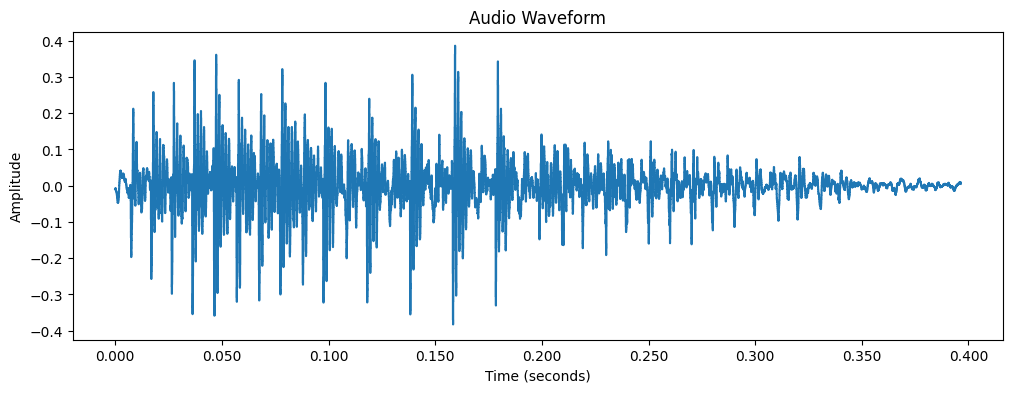

In [3]:
# Select one sample recording
sample_file = os.listdir(DATASET_PATH)[0]

sample_path = os.path.join(
    DATASET_PATH,
    sample_file
)

audio, sr = librosa.load(
    sample_path,
    sr=16000
)

duration = len(audio) / sr

print("Sample file:", sample_file)
print("Sampling rate:", sr)
print("Audio duration:", round(duration, 3), "seconds")
print("Number of audio samples:", len(audio))

# Plot waveform
plt.figure(figsize=(12, 4))

librosa.display.waveshow(audio, sr=sr)

plt.title("Audio Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.show()

## 4. Sequential Preprocessing Using MFCC

MFCC stands for Mel-Frequency Cepstral Coefficients.

MFCC is commonly used in speech processing
to represent the characteristics of speech.

Why do we use MFCC?

Raw audio contains a large number of samples.
MFCC converts audio into a smaller set of
meaningful numerical features.

Steps:

1. Divide audio into short overlapping frames.
2. Apply windowing.
3. Calculate the frequency spectrum.
4. Apply the Mel filter bank.
5. Calculate logarithmic energies.
6. Apply the Discrete Cosine Transform (DCT).

We extract 13 MFCC coefficients per frame.

Therefore, every recording becomes a sequence
of 13-dimensional observation vectors.

IMPORTANT:
We preserve the chronological order of frames
because HMM learns temporal relationships.

In [4]:
def extract_mfcc(file_path):

    audio, sr = librosa.load(
        file_path,
        sr=16000
    )

    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=13,
        n_fft=512,
        hop_length=160
    )

    # Transpose so each row represents one time frame
    mfcc = mfcc.T

    return mfcc


sample_mfcc = extract_mfcc(sample_path)

print("MFCC shape:", sample_mfcc.shape)

print("Number of time frames:", sample_mfcc.shape[0])

print("Features per frame:", sample_mfcc.shape[1])

MFCC shape: (40, 13)
Number of time frames: 40
Features per frame: 13


## 5. MFCC Visualization

We visualize the extracted MFCC features.

The horizontal axis represents time frames.

The vertical axis represents the 13 MFCC coefficients.

Different speech sounds produce different
patterns in the MFCC representation.

This visualization helps us understand
how audio is transformed into sequential
numerical observations.

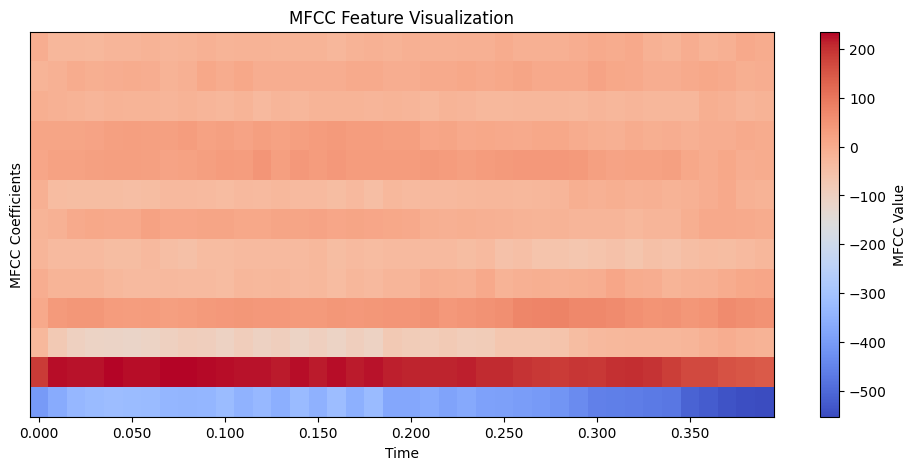

In [5]:
plt.figure(figsize=(12, 5))

librosa.display.specshow(
    sample_mfcc.T,
    x_axis="time",
    sr=16000,
    hop_length=160
)

plt.colorbar(label="MFCC Value")

plt.title("MFCC Feature Visualization")

plt.xlabel("Time")
plt.ylabel("MFCC Coefficients")

plt.show()

## 6. Preparing Sequential Data

We now process all audio recordings.

For each recording:

1. Extract the digit label from its filename.
2. Load the audio file.
3. Extract its MFCC sequence.
4. Store the sequence and its corresponding label.

Each recording has a different number of time frames.

We preserve the complete sequence for each recording.

We do NOT flatten all recordings into one
large feature vector because that would
remove the temporal structure required by HMM.

We also keep recordings separate for training
and testing to avoid data leakage.

In [6]:
sequences = []
labels = []
speakers = []

for filename in os.listdir(DATASET_PATH):

    if not filename.endswith(".wav"):
        continue

    file_path = os.path.join(
        DATASET_PATH,
        filename
    )

    # Filename format: digit_speaker_index.wav
    parts = filename.replace(".wav", "").split("_")

    digit = int(parts[0])
    speaker = parts[1]

    mfcc = extract_mfcc(file_path)

    sequences.append(mfcc)
    labels.append(digit)
    speakers.append(speaker)

labels = np.array(labels)
speakers = np.array(speakers)

print("Total recordings:", len(sequences))

print("\nDigit distribution:")
print(pd.Series(labels).value_counts().sort_index())

print("\nExample sequence shape:", sequences[0].shape)

Total recordings: 3000

Digit distribution:
0    300
1    300
2    300
3    300
4    300
5    300
6    300
7    300
8    300
9    300
Name: count, dtype: int64

Example sequence shape: (40, 13)


## 7. Training and Testing Split

We split the recordings into:

- 80% training data.
- 20% testing data.

The training data is used to learn the HMM parameters.

The testing data is used to measure how well
the trained models recognize unseen recordings.

We use stratification so each digit is represented
in both training and testing sets.

We use a fixed random state to make the experiment
reproducible.

In [7]:
indices = np.arange(len(labels))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

X_train = [sequences[i] for i in train_idx]
X_test = [sequences[i] for i in test_idx]

y_train = labels[train_idx]
y_test = labels[test_idx]

print("Training recordings:", len(X_train))
print("Testing recordings:", len(X_test))

print("\nTraining digit distribution:")
print(pd.Series(y_train).value_counts().sort_index())

Training recordings: 2400
Testing recordings: 600

Training digit distribution:
0    240
1    240
2    240
3    240
4    240
5    240
6    240
7    240
8    240
9    240
Name: count, dtype: int64


## 8. Understanding Hidden Markov Models

A Hidden Markov Model is a probabilistic model
used to represent sequential data.

It consists of:

1. Hidden States:
   Internal states that cannot be directly observed.

2. Observations:
   The visible MFCC feature vectors extracted
   from the audio.

3. Initial State Probabilities:
   Probability of starting in each hidden state.

4. Transition Probabilities:
   Probability of moving from one hidden state
   to another.

5. Emission Probabilities:
   Probability of generating an observation
   from a particular hidden state.

In our project:

- Hidden states represent internal speech stages.
- Observations represent MFCC feature vectors.
- Transitions represent how speech states change.
- Emissions represent the acoustic features
  associated with each state.

We train a separate Gaussian HMM for every digit.

The model with the highest sequence likelihood
is selected as the predicted digit.

## 9. HMM Model Training

We train 10 different Gaussian Hidden Markov Models.

Each model represents one spoken digit:

HMM 0 → Digit 0
HMM 1 → Digit 1
...
HMM 9 → Digit 9

We use GaussianHMM because MFCC features
are continuous numerical observations.

Each model learns:

- Initial state probabilities.
- Transition probability matrix.
- Gaussian emission parameters.

We use 5 hidden states for each digit.

The number of hidden states is a hyperparameter
that can be adjusted experimentally.

In [9]:
models = {}

for digit in range(10):

    digit_sequences = [
        X_train[i]
        for i in range(len(X_train))
        if y_train[i] == digit
    ]

    # Total number of frames across all recordings
    lengths = [
        len(sequence)
        for sequence in digit_sequences
    ]

    # Combine sequences while preserving their boundaries
    combined_data = np.vstack(digit_sequences)

    model = hmm.GaussianHMM(
        n_components=5,
        covariance_type="diag",
        n_iter=100,
        random_state=42,
        min_covar=0.01
    )

    model.fit(
        combined_data,
        lengths=lengths
    )

    models[digit] = model

    print(f"HMM trained for digit {digit}")

print("\nAll 10 HMM models trained successfully!")

HMM trained for digit 0
HMM trained for digit 1
HMM trained for digit 2
HMM trained for digit 3
HMM trained for digit 4
HMM trained for digit 5
HMM trained for digit 6
HMM trained for digit 7
HMM trained for digit 8
HMM trained for digit 9

All 10 HMM models trained successfully!


## 10. Understanding Transition Probabilities

The transition matrix represents the probability
of moving from one hidden state to another.

For example:

A state may transition to itself or to another state.

Each row of the transition matrix represents
the probabilities of moving from one current state
to all possible next states.

The probabilities in each row sum approximately to 1.

We visualize the transition matrix of the
HMM trained for digit 5.

Transition Matrix for Digit 5:
[[8.82920420e-001 7.70855154e-002 9.90338716e-052 3.99940641e-002
  9.30243542e-031]
 [1.88321297e-030 9.43278845e-001 2.80043490e-002 3.17187664e-003
  2.55449290e-002]
 [9.25322140e-141 4.04475742e-185 9.19581208e-001 2.38100624e-002
  5.66087297e-002]
 [1.60771999e-003 2.87577338e-002 1.81574573e-002 9.50316558e-001
  1.16053040e-003]
 [9.64563574e-002 1.33975886e-077 3.09227716e-023 3.46332639e-012
  9.03543643e-001]]


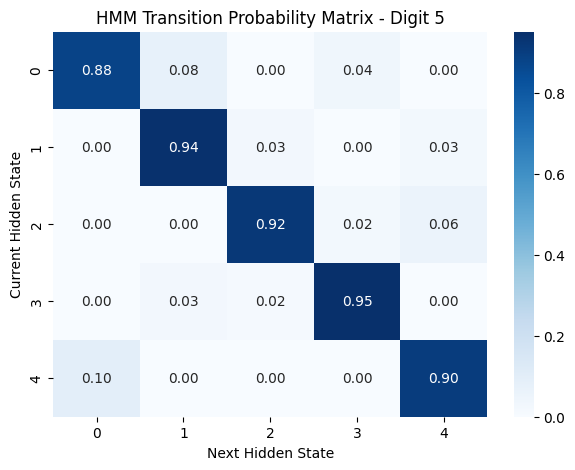

In [10]:
transition_matrix = models[5].transmat_

print("Transition Matrix for Digit 5:")
print(transition_matrix)

plt.figure(figsize=(7, 5))

sns.heatmap(
    transition_matrix,
    annot=True,
    cmap="Blues",
    fmt=".2f"
)

plt.title("HMM Transition Probability Matrix - Digit 5")

plt.xlabel("Next Hidden State")
plt.ylabel("Current Hidden State")

plt.show()

## 11. Forward and Backward Algorithms

The Forward and Backward algorithms are used
to calculate probabilities in Hidden Markov Models.

### Forward Algorithm

The Forward algorithm calculates the probability
of observing a sequence given an HMM.

In speech recognition, it helps us determine
how likely an audio sequence is under a particular
digit model.

### Backward Algorithm

The Backward algorithm calculates the probability
of the remaining observations given the current state.

It works backward through the observation sequence.

### In Our Implementation

The hmmlearn library provides score_samples(),
which calculates the sequence log likelihood
using the Forward algorithm and state posterior
probabilities using Forward-Backward computation.

The posterior probabilities help us understand
which hidden states are likely at different
time frames.

Log likelihood: -3354.0462952306066
Posterior probability shape: (56, 5)

First 5 time frames:
[[2.22168746e-123 1.00000000e+000 9.99166885e-042 3.35847246e-015
  4.57353023e-106]
 [2.48275272e-040 1.00000000e+000 8.36191876e-041 3.17959172e-016
  7.10817146e-069]
 [9.78977821e-045 1.00000000e+000 2.70671651e-040 1.37369628e-015
  3.44900540e-070]
 [2.79135815e-043 1.00000000e+000 2.64826371e-041 2.71469477e-014
  1.38486879e-068]
 [5.86087476e-037 1.00000000e+000 1.62255410e-038 8.33971101e-014
  5.52439836e-062]]


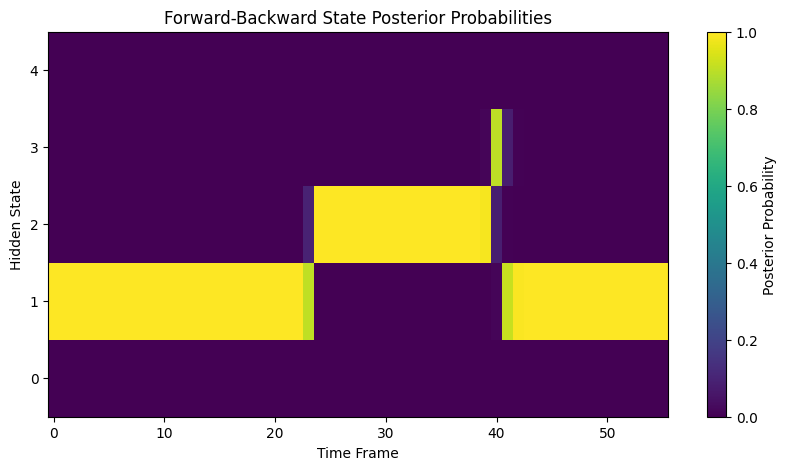

In [11]:
# Use one testing recording
sample_sequence = X_test[0]

# Select HMM model for digit 5
model = models[5]

# Forward probability and posterior probabilities
log_probability, posterior = model.score_samples(
    sample_sequence
)

print("Log likelihood:", log_probability)

print("Posterior probability shape:", posterior.shape)

print("\nFirst 5 time frames:")
print(posterior[:5])

# Visualize posterior probabilities
plt.figure(figsize=(10, 5))

plt.imshow(
    posterior.T,
    aspect="auto",
    origin="lower",
    cmap="viridis"
)

plt.colorbar(label="Posterior Probability")

plt.xlabel("Time Frame")
plt.ylabel("Hidden State")

plt.title("Forward-Backward State Posterior Probabilities")

plt.show()

## 12. Viterbi Algorithm

The Viterbi algorithm finds the most probable
sequence of hidden states for a given observation sequence.

Unlike the Forward algorithm, which calculates
the total probability of all possible state paths,
Viterbi identifies the single most likely path.

In our speech recognition system:

- Input: MFCC observation sequence.
- HMM: Model trained for a particular digit.
- Output: Most probable sequence of hidden states.

The hmmlearn decode() method implements
the Viterbi algorithm when algorithm="viterbi"
is specified.

Viterbi log probability: -3354.2510778921333

Most probable hidden state sequence:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 3 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]

Number of hidden states: 56


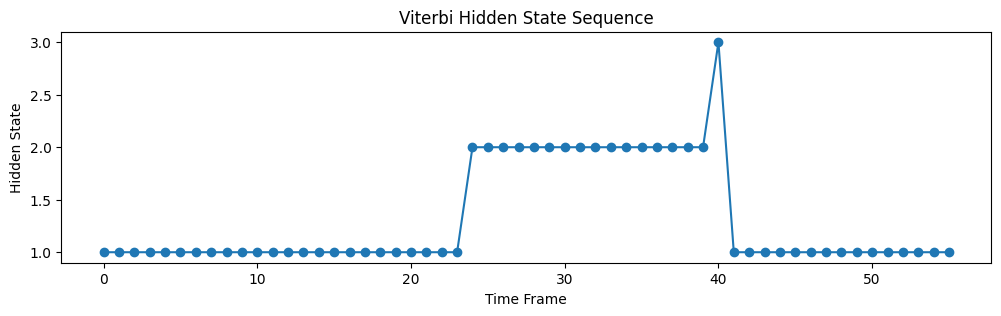

In [12]:
# Decode a sample recording using Viterbi
log_prob, hidden_states = models[5].decode(
    sample_sequence,
    algorithm="viterbi"
)

print("Viterbi log probability:", log_prob)

print("\nMost probable hidden state sequence:")
print(hidden_states)

print("\nNumber of hidden states:", len(hidden_states))

# Plot hidden state sequence
plt.figure(figsize=(12, 3))

plt.plot(hidden_states, marker="o")

plt.title("Viterbi Hidden State Sequence")
plt.xlabel("Time Frame")
plt.ylabel("Hidden State")

plt.show()

## 13. Speech Recognition and Prediction

Now we use the trained HMM models to recognize
the spoken digit.

For every test recording:

1. Pass its MFCC sequence to all 10 HMMs.
2. Calculate the log likelihood under each model.
3. Normalize the log likelihood by sequence length.
4. Select the model with the highest normalized score.
5. Return the corresponding digit as the prediction.

The highest score indicates the model that
best explains the observed audio sequence
among the trained digit models.

In [13]:
def predict_digit(sequence, models):

    scores = {}

    for digit, model in models.items():

        # Calculate log likelihood
        log_score = model.score(sequence)

        # Normalize by number of frames
        normalized_score = log_score / len(sequence)

        scores[digit] = normalized_score

    predicted_digit = max(
        scores,
        key=scores.get
    )

    return predicted_digit


# Test one recording
sample_prediction = predict_digit(
    sample_sequence,
    models
)

print("Actual digit:", y_test[0])
print("Predicted digit:", sample_prediction)

Actual digit: 4
Predicted digit: 4


## 14. Model Evaluation

We evaluate the speech recognition model
using the testing dataset.

Evaluation metrics:

1. Accuracy:
   Percentage of correctly recognized digits.

2. Precision:
   Measures how many predicted instances
   of a digit are correct.

3. Recall:
   Measures how many actual instances
   of a digit are correctly identified.

4. F1-score:
   Harmonic mean of precision and recall.

We also use a confusion matrix to visualize
correct and incorrect predictions.

These metrics help us understand the
performance of the HMM speech recognition system.

In [14]:
y_pred = []

for sequence in X_test:

    prediction = predict_digit(
        sequence,
        models
    )

    y_pred.append(prediction)

y_pred = np.array(y_pred)

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Speech Recognition Accuracy:",
      round(accuracy * 100, 2), "%")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        labels=list(range(10)),
        zero_division=0
    )
)

Speech Recognition Accuracy: 90.67 %

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.92      0.93        60
           1       0.80      0.95      0.87        60
           2       0.83      0.92      0.87        60
           3       0.76      0.85      0.80        60
           4       0.98      0.88      0.93        60
           5       0.98      0.90      0.94        60
           6       0.98      0.75      0.85        60
           7       0.98      0.98      0.98        60
           8       0.92      0.95      0.93        60
           9       0.95      0.97      0.96        60

    accuracy                           0.91       600
   macro avg       0.91      0.91      0.91       600
weighted avg       0.91      0.91      0.91       600



## 15. Confusion Matrix Visualization

A confusion matrix compares the actual digit
with the predicted digit.

Rows represent actual digits.

Columns represent predicted digits.

Diagonal values represent correct predictions.

Values outside the diagonal represent
incorrect predictions.

This visualization helps identify which digits
are being confused with one another.

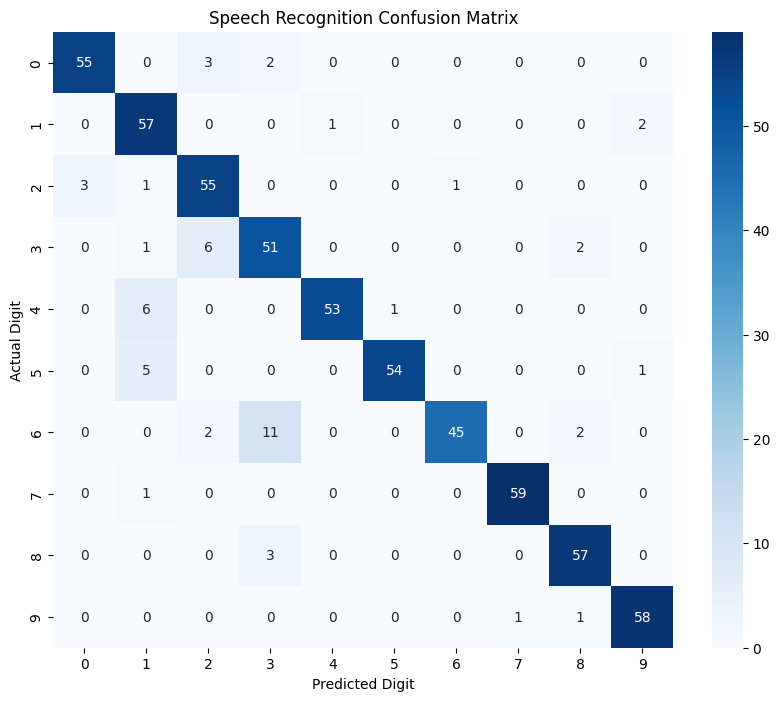

In [15]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=list(range(10))
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")

plt.title("Speech Recognition Confusion Matrix")

plt.show()

## 16. Actual vs Predicted Results

We compare a few actual spoken digits
with the predictions made by the HMM system.

This gives a simple demonstration of
the speech recognition output.

In [16]:
results = pd.DataFrame({
    "Actual Digit": y_test[:20],
    "Predicted Digit": y_pred[:20]
})

results["Correct"] = (
    results["Actual Digit"] ==
    results["Predicted Digit"]
)

display(results)

,Actual Digit,Predicted Digit,Correct
0,4,4,True
1,0,0,True
2,1,1,True
3,4,1,False
4,9,9,True
5,3,3,True
6,4,4,True
7,8,8,True
8,7,7,True
9,2,2,True


## 17. Conclusion

In this project, we developed a speech recognition
system using Hidden Markov Models.

The Free Spoken Digit Dataset was used to train
and test the system.

MFCC was used to extract meaningful audio features
while preserving their temporal order.

Ten Gaussian HMM models were trained,
one for each digit from 0 to 9.

The Forward algorithm was used to calculate
observation sequence likelihoods.

The Forward-Backward computation was used
to obtain hidden-state posterior probabilities.

The Viterbi algorithm was used to identify
the most probable hidden-state sequence.

The model was evaluated using accuracy,
precision, recall, F1-score and a confusion matrix.

### Applications

- Voice-controlled applications.
- Automated speech recognition.
- Voice-based interfaces.
- Speech-enabled assistive technologies.

### Future Scope

The system can be improved by using:
- More speech recordings.
- Different speakers and accents.
- Delta and delta-delta MFCC features.
- Different numbers of hidden states.
- Advanced speech recognition models.